# v6 analysis B (GPU 1): the new analyses (lesion+relearn, crosscoder, Goodfire, Self-Preservation)
**Before running:** stop the training notebooks (Kernel → Interrupt). Then **Run All**. About 45–60 min. Runs on the reference models (phase 45), so it does not depend on tonight's training.

| part | idea | question |
|---|---|---|
| relearn | robot paper: lesion, then let it relearn | reset 20% of neurons from the self vs from task neurons vs random, then train the same language: which hurts more, which recovers slower? |
| crosscoder | model diffing (Anthropic, Lindsey et al. 2024) | one set of features for two checkpoints: which features are shared, which are new? Are self neurons fed mostly by shared features? |
| ends | Goodfire 1 | the tokens at both ends of a neuron (most positive / most negative input): do they form a contrast? |
| widen | Goodfire 2 | following the same neuron over 11 checkpoints: does its job widen to related tokens, or jump to unrelated ones? self vs task |
| steer | Goodfire 3 | force a neuron on while translating: does the output shift to the tokens that neuron fires on? |
| sentences | Self-Preservation (Cho et al.) | at a switch, which test sentences are forgotten, and do they rely more on task neurons than on self neurons? |

In [1]:
import os, sys, glob, json, time, subprocess
GPU = "1"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    """Make sure runs/<run>/ckpt/pXXX_*.pt exists for each phase (download from HF if missing)."""
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("not on HF:", run, ph)

def run(*cmd):
    """Run a script and show its output here, line by line."""
    p = subprocess.Popen([sys.executable, "-u", *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

def phases_of(run):
    return sorted(int(os.path.basename(p)[1:4]) for p in glob.glob(f"runs/{run}/ckpt/p*.pt"))

FIX, Q2 = "v6_cont_noise0.0007_from60", "v6_hi_push0.6_from30"
REF_C, REF_H = "v4b_continual_s0", "v4b_only_hi_s0"
for r in [FIX, Q2]:
    print(f"{r:<30} trained phases: {[p for p in phases_of(r) if p > (60 if r == FIX else 30)]}")
for r in [REF_C, REF_H]:
    print(f"{r:<30} analysis files in repo: {len(glob.glob(f'analysis/v5/{r}/p*.npz'))} (should be ~90)")

v6_cont_noise0.0007_from60     trained phases: [61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86]
v6_hi_push0.6_from30           trained phases: [31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58]
v4b_continual_s0               analysis files in repo: 87 (should be ~90)
v4b_only_hi_s0                 analysis files in repo: 91 (should be ~90)


In [2]:
# checkpoints needed: the switch 44 -> 45 (both runs) and every 3rd phase 30..60 for "widen"
WIDEN = list(range(30, 61, 3))
for r in [REF_C, REF_H]:
    get(r, sorted(set([44, 45] + WIDEN)))
print("ok")

ok


In [3]:
run("analysis_v6_deep.py", "--gpu", GPU, "--phase", "45", "--widen_phases", ",".join(map(str, WIDEN)), "--tag", "ref_p45")

analysis_v6_deep | runs {'continual': 'v4b_continual_s0', 'hindi': 'v4b_only_hi_s0'} | phase 45 | tau 0.2 | parts ['relearn', 'crosscoder', 'ends', 'widen', 'steer', 'sentences'] | out /workspace/shreshth/analysis/v6/deep_ref_p45

=== 1. LESION + RELEARN: reset 20% of each MLP layer, then train the same language ===
  continual  reset self  : loss rise right after = 0.520, after 400 steps = 0.239
  continual  reset task  : loss rise right after = 0.247, after 400 steps = 0.224
  continual  reset random: loss rise right after = 0.294, after 400 steps = 0.240
  hindi      reset self  : loss rise right after = 0.770, after 400 steps = 0.206
  hindi      reset task  : loss rise right after = 0.365, after 400 steps = 0.188
  hindi      reset random: loss rise right after = 0.492, after 400 steps = 0.192
  [relearn took 8.2 min]

=== 2. CROSSCODER (model diffing) ===
  continual switch                       enc1.mlp: shared  100%  A-only   0%  B-only   0%  | input from shared features: self 

## Results

analysis_v6_deep | runs {'continual': 'v4b_continual_s0', 'hindi': 'v4b_only_hi_s0'} | phase 45 | tau 0.2 | parts ['relearn', 'crosscoder', 'ends', 'widen', 'steer', 'sentences'] | out /workspace/shreshth/analysis/v6/deep_ref_p45

=== 1. LESION + RELEARN: reset 20% of each MLP layer, then train the same language ===
  continual  reset self  : loss rise right after = 0.520, after 400 steps = 0.239
  continual  reset task  : loss rise right after = 0.247, after 400 steps = 0.224
  continual  reset random: loss rise right after = 0.294, after 400 steps = 0.240
  hindi      reset self  : loss rise right after = 0.770, after 400 steps = 0.206
  hindi      reset task  : loss rise right after = 0.365, after 400 steps = 0.188
  hindi      reset random: loss rise right after = 0.492, after 400 steps = 0.192
  [relearn took 8.2 min]

=== 2. CROSSCODER (model diffing) ===
  continual switch                       enc1.mlp: shared  100%  A-only   0%  B-only   0%  | input from shared features: self 

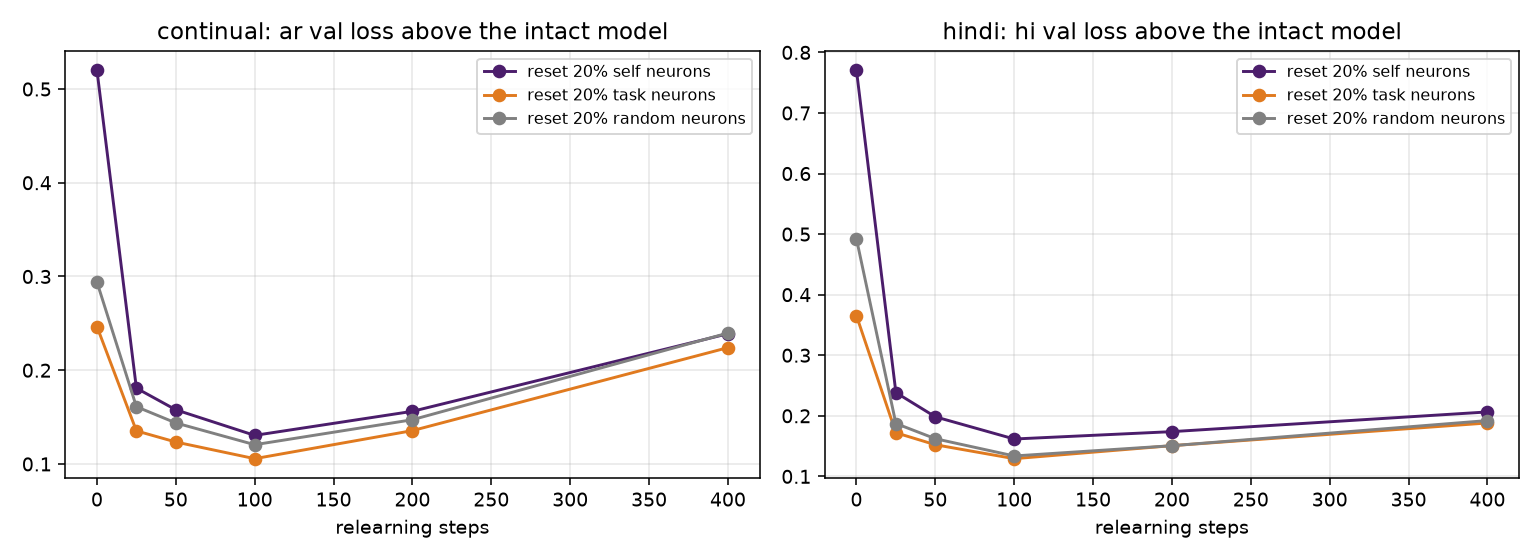

crosscoder_hist


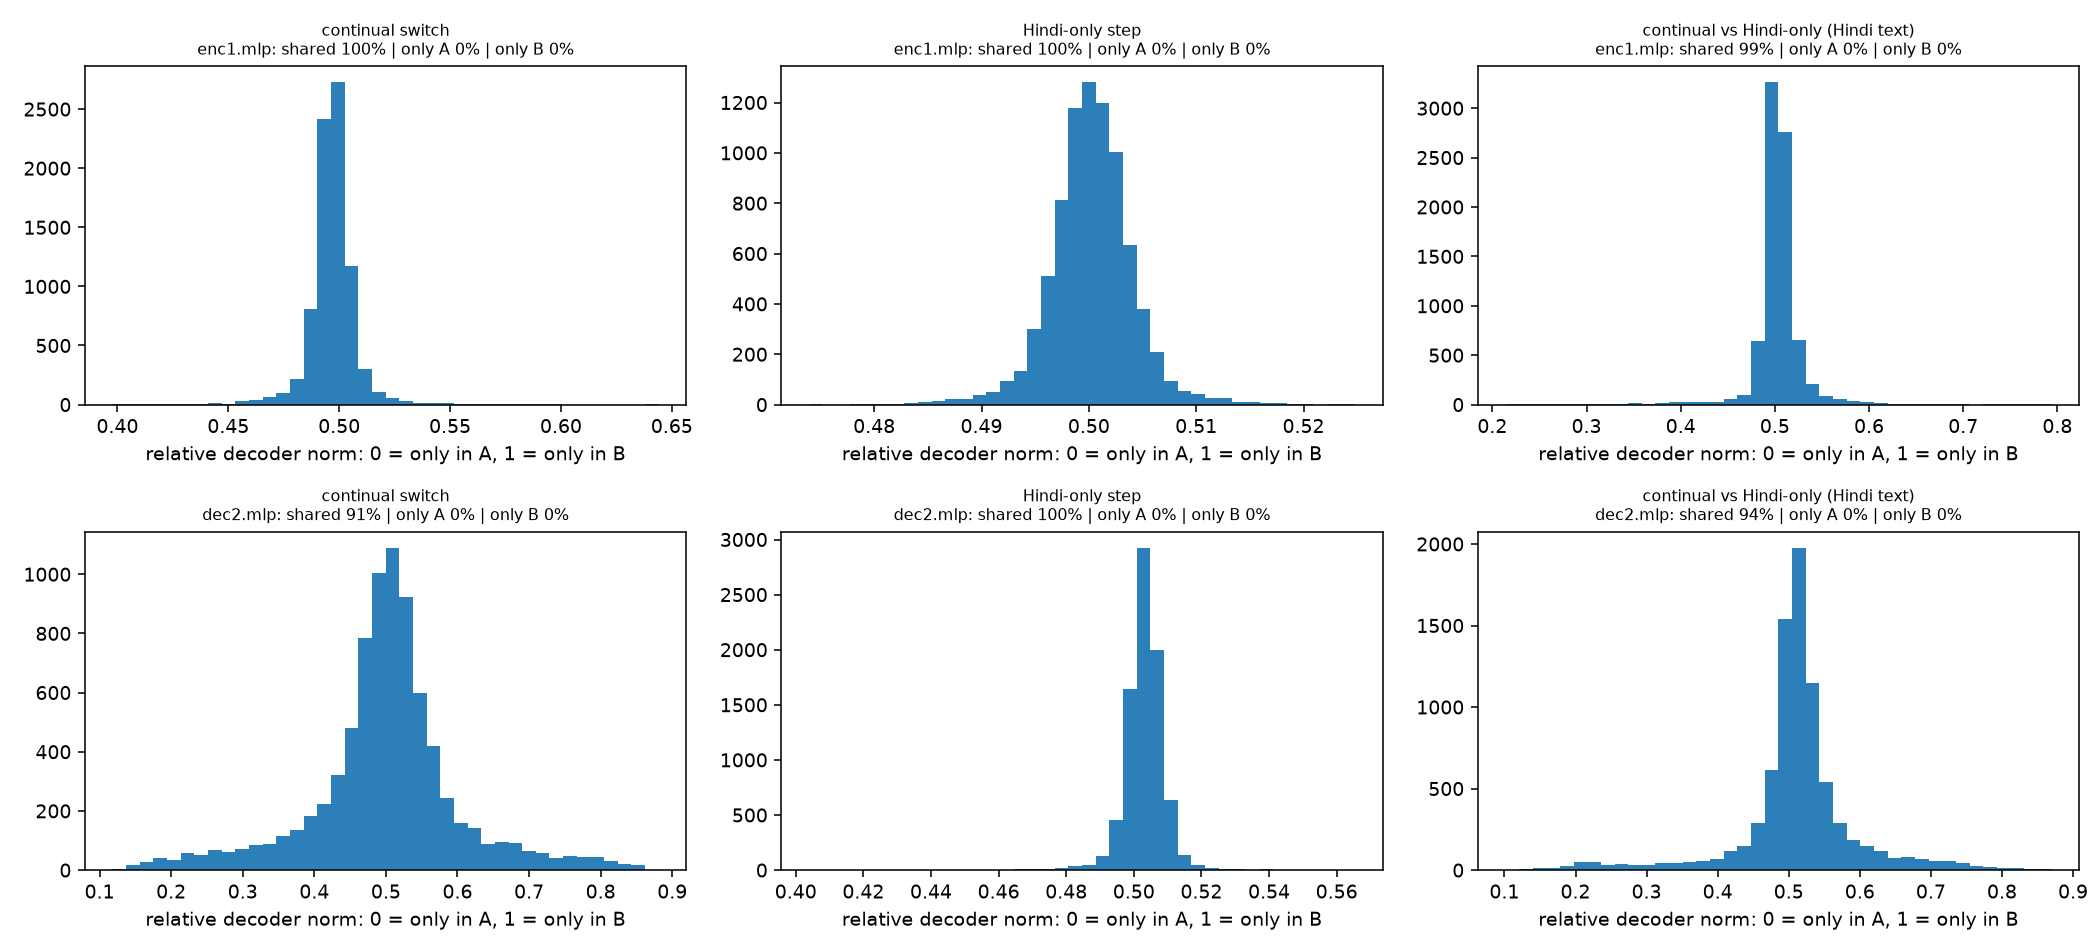

widen


In [ ]:
OUTD = "analysis/v6/deep_ref_p45"
print(open(f"{OUTD}/report.txt").read())
for f in ["relearn", "crosscoder_hist", "widen", "sentences"]:
    if os.path.exists(f"{OUTD}/{f}.png"):
        print(f); display(Image(f"{OUTD}/{f}.png"))

In [ ]:
# the token tables, to read by eye
import pandas as pd
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)
display(pd.read_csv(f"{OUTD}/ends.csv").head(24))
display(pd.read_csv(f"{OUTD}/steer.csv")[["run", "group", "neuron", "top5", "share_top5_base", "share_top5_forced", "chrf_base", "chrf_forced"]])

## Optional (only if time): relearn + steer on the FIX run vs the original continual run, at the fix run's latest phase
Uses GPU 1 after the main part is done. Answers: with the plasticity fix, is the self still more important than task neurons?

In [ ]:
ph = [p for p in phases_of(FIX) if p > 60][-1]
get(REF_C, [ph - 1, ph])
run("analysis_v6_deep.py", "--gpu", GPU, "--parts", "relearn", "steer", "--cont", FIX, "--hi", REF_C, "--phase", str(ph), "--tag", f"fix_p{ph}", "--labels", "fix,continual (ref)")
print(open(f"analysis/v6/deep_fix_p{ph}/report.txt").read())
display(Image(f"analysis/v6/deep_fix_p{ph}/relearn.png"))

  fix        reset self  : loss rise right after = 0.333, after 400 steps = 0.184
  fix        reset task  : loss rise right after = 0.242, after 400 steps = 0.121
  fix        reset random: loss rise right after = 0.351, after 400 steps = 0.193
  continual (ref) reset self  : loss rise right after = 0.337, after 400 steps = 0.184
  continual (ref) reset task  : loss rise right after = 0.323, after 400 steps = 0.158
  continual (ref) reset random: loss rise right after = 0.363, after 400 steps = 0.195
  [relearn took 7.9 min]

=== 5. GOODFIRE: force a neuron on while translating ===
